In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [1]:
import torch
import torchvision
import diffusers
import transformers
import accelerate
import safetensors
import scipy
import pandas as pd
import pickle
from diffusers import StableDiffusionPipeline
import pandas as pd
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_distances
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score  


/Users/ahz/miniforge3/envs/py311_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AttributeError: module 'pyarrow' has no attribute '__version__'

In [39]:
#https://www.ef.com/wwen/english-resources/english-vocabulary/top-1000-words/
words=pd.read_csv("words_alpha.txt",header=None)
words=np.array(list(words[0]))

Initial Reservoir:
  [0] As she sat on the couch, watching the old film, the woman couldn't help but thin
  [1] As we sat together, I sought his opinion on my latest creative project, and our 
  [2] As she stepped into the sweltering heat, Emma realized that to truly go forward,
  [3] As the morning sun rises over the nation, eight weary travelers prepare to embar
  [4] As I sat particularly alone, surrounded by nature, I found an old book with exac
  [5] On the former baseball field, a measure of grass remains green, its worn base no
  [6] A former accountant sat at the window, lost in thought, willing to give up her o
  [7] The cell's idea germinated before its mother, a fertile environment that nurture
  [8] A wealthy individual, then, wondered why they worked tirelessly for minimal gain
  [9] The solitary figure stood still at the center, holding a faded message that read
  [10] In the bustling marketplace, many vendors gathered to compare their wares, as a 
  [11] As I plan my hik

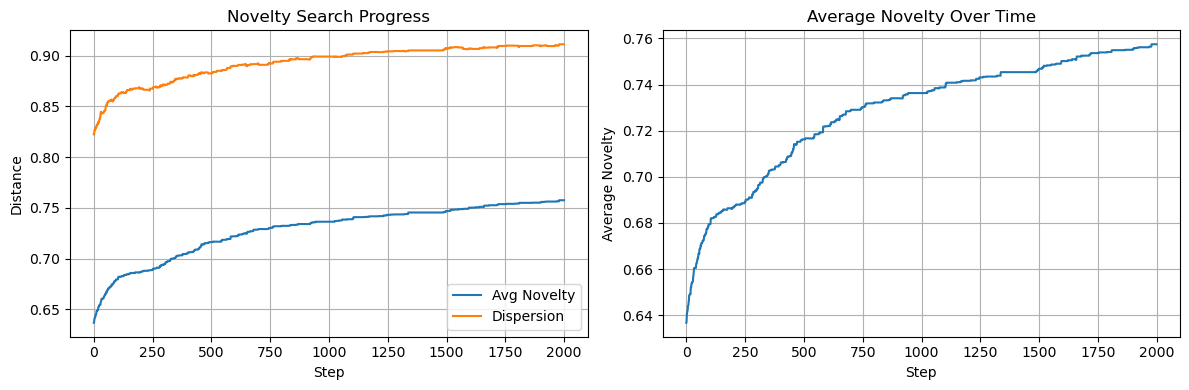

In [70]:
import random
import numpy as np
from sklearn.metrics.pairwise import cosine_distances
from sentence_transformers import SentenceTransformer
import ollama
import matplotlib.pyplot as plt

# Parameters
N = 100     # Reservoir size
R = 2000    # Search iterations
k = 10      # How many neighbors to average for novelty scoring
TEMPERATURE = 0.9

# Initialize embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")
changes = []

# Generate prompt using LLM
def generate_prompt(l=5):
    wordlist = list(words[np.random.choice(range(len(words)), (l), replace=False)])
    prompt = f"Use the following words as an inspiration to describe a simple scene in single sentence of 30 words or less: {wordlist} Only return the sentence."
    response = ollama.generate(
        model="llama3.2",
        prompt=prompt,
        options={"temperature": TEMPERATURE}
    )
    return response["response"].strip()

# Modify an existing prompt
def modify_prompt(original):
    wordlist = list(words[np.random.choice(range(len(words)), (2), replace=False)])
    prompt = f"Modify this simple scene description {original} and use these words as inspiration: {wordlist} Keep it one sentence and under 30 words!"
    response = ollama.generate(
        model="llama3.2",
        prompt=prompt,
        options={"temperature": TEMPERATURE}
    )
    return response["response"].strip()

# Compute novelty scores
def compute_novelty_scores(embeddings, k):
    dists = cosine_distances(embeddings)
    np.fill_diagonal(dists, np.inf)
    sorted_dists = np.sort(dists, axis=1)
    scores = sorted_dists[:, :k].mean(axis=1)  # average distance to k nearest neighbors
    return scores

# Compute novelty score for a single new embedding against existing ones
def compute_single_novelty(new_embedding, existing_embeddings, k):
    dists = cosine_distances([new_embedding], existing_embeddings)[0]
    sorted_dists = np.sort(dists)
    return sorted_dists[:k].mean()  # average distance to k nearest neighbors

# Initialize reservoir
reservoir = [generate_prompt() for _ in range(N)]
reservoir_embeddings = [model.encode(p) for p in reservoir]
novelty_history = []
dispersion = []
replacements_made = 0

print("Initial Reservoir:")
initialReservoir=[]
for i, prompt in enumerate(reservoir):
    print(f"  [{i}] {prompt[:80]}")
    initialReservoir.append(prompt)

# Novelty Search Loop
for step in range(R):
    scores = compute_novelty_scores(reservoir_embeddings, k)
    least_novel_idx = np.argmin(scores)
    least_novel_score = scores[least_novel_idx]
    
    # Pick a source to mutate (can be least novel or random)
    source_idx = random.randint(0, N - 1)
    new_prompt = modify_prompt(reservoir[source_idx])
    new_vec = model.encode(new_prompt)
    
    # Compute novelty score for the new prompt
    new_novelty_score = compute_single_novelty(new_vec, reservoir_embeddings, k)
    
    # Only replace if the new prompt is more novel than the least novel one
    if new_novelty_score > least_novel_score:
        changes.append([least_novel_idx,new_prompt])
        reservoir[least_novel_idx] = new_prompt
        reservoir_embeddings[least_novel_idx] = new_vec
        replacements_made += 1
        change_made = True
    else:
        change_made = False
    
    # Recompute scores after potential replacement
    scores = compute_novelty_scores(reservoir_embeddings, k)
    avg_novelty = scores.mean()
    novelty_history.append(avg_novelty)
    
    if step % 100 == 0:
        #if True:
        status = "✓ REPLACED" if change_made else "✗ rejected"
        print(f"[{step+1:03}] {status} | new novelty: {new_novelty_score:.3f} vs least: {least_novel_score:.3f}")
        print(f"      ⤷ avg novelty: {avg_novelty:.3f} | replacements so far: {replacements_made}")
    
    # Compute dispersion
    dists = cosine_distances(np.array(reservoir_embeddings))
    triu = np.triu_indices_from(dists, k=1)
    dispersion.append(dists[triu].mean())

print(f"\nFinal stats: {replacements_made}/{R} replacements made ({replacements_made/R*100:.1f}%)")

# Plot novelty over time
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(novelty_history, label='Avg Novelty')
plt.plot(dispersion, label='Dispersion')
plt.xlabel("Step")
plt.ylabel("Distance")
plt.legend()
plt.grid(True)
plt.title("Novelty Search Progress")

plt.subplot(1, 2, 2)
plt.plot(novelty_history)
plt.xlabel("Step")
plt.ylabel("Average Novelty")
plt.grid(True)
plt.title("Average Novelty Over Time")
plt.tight_layout()
plt.show()

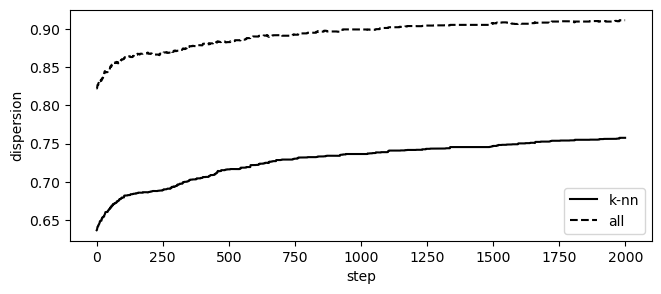

In [71]:
# Plot novelty over time
plt.figure(figsize=(7.5, 3))
plt.plot(novelty_history,'k',label="k-nn")
plt.plot(dispersion,'k--',label='all')
plt.xlabel("step")
plt.ylabel("dispersion")
#plt.grid(True)
plt.legend()
plt.show()


In [74]:
pickle.dump(reservoir,open("reservoir_100.pkl","wb"))
pickle.dump(initialReservoir,open("initialReservoir_100.pkl","wb"))
pickle.dump(changes,open("changesReservoir_100.pkl","wb"))

In [81]:
A=list(copy(initialReservoir))
for i,p in changes:
    A.append(p)

all_embeddings=dict()
for a in A:
    all_embeddings[a]=model.encode(a)
    


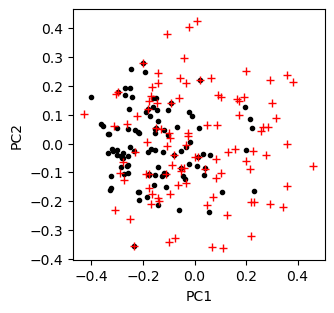

In [96]:
alpha=[]
for p in initialReservoir:
    alpha.append(all_embeddings[p])
omega=[]
for p in reservoir:
    omega.append(all_embeddings[p])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(numpy.array(list(omega)))
ALPHA=pca.transform(alpha).transpose()
OMEGA=pca.transform(omega).transpose()
figure(figsize=[3.25,3.25])
plot(ALPHA[0],ALPHA[1],'.k')
plot(OMEGA[0],OMEGA[1],'+r')
xlabel("PC1")
ylabel("PC2")
savefig("alhpaOmegaPCA.pdf")
show()

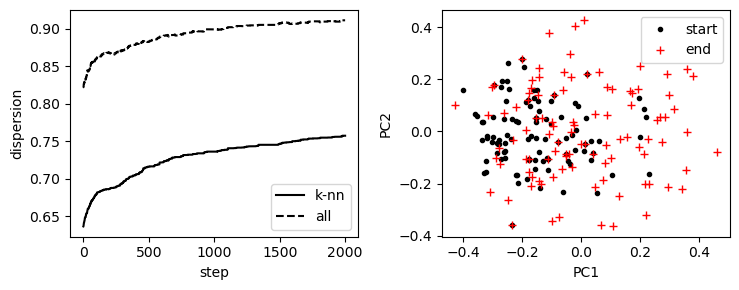

In [102]:
# Plot novelty over time
plt.figure(figsize=(7.5, 3))
plt.subplot(1,2,1)
plt.plot(novelty_history,'k',label="k-nn")
plt.plot(dispersion,'k--',label='all')
plt.xlabel("step")
plt.ylabel("dispersion")
#plt.grid(True)
plt.legend()
plt.subplot(1,2,2)
plt.plot(ALPHA[0],ALPHA[1],'.k',label='start')
plt.plot(OMEGA[0],OMEGA[1],'+r',label='end')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.savefig("noveltyOptimization.pdf")
plt.show()

In [3]:
reservoir=pickle.load(open("reservoir_100.pkl","rb"))

In [4]:
from PIL import Image
import math
import os

In [22]:


for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
    for who in range(100):
        pathImage=Image.new("RGB", (64*10,64*10), color=(12, 12, 12))
        i=0
        for y in range(10):
            for x in range(10):
                try:
                    img=Image.open(f"temps/images/run_{who:03}_rep_0_step_{i:03}_temp_{temp}.png").convert("RGB")
                    resized = img.resize((64,64), Image.LANCZOS)
                    pathImage.paste(resized, (64*x,64*y))
                except Exception:
                    pass
                i+=1
        pathImage.save(f"pathImages/pathImage_{who}_{temp}.png")


In [23]:
for doStart in [True,False]:
    for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
        pathImage=Image.new("RGB", (64*10,64*10), color=(255, 255, 255))
        who=0
        for x in range(10):
            for y in range(10):
                try:
                    if doStart:
                        img=Image.open(f"temps/images/run_{who:03}_rep_0_step_000_temp_{temp}.png").convert("RGB")
                    else:
                        img=Image.open(f"temps/images/run_{who:03}_rep_0_step_099_temp_{temp}.png").convert("RGB")
                    resized = img.resize((64,64), Image.LANCZOS)
                    pathImage.paste(resized, (64*x,64*y))
                except Exception:
                    pass
                who+=1
        if doStart:
            pathImage.save(f"pathImages/pathImage_START_{temp}.png")
        else:
            pathImage.save(f"pathImages/pathImage_END_{temp}.png")

In [33]:
pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None)
pipe = pipe.to("mps")

# Generate image from prompt
def generate_image(prompt):
    image = pipe(prompt, num_inference_steps=25).images[0]

    return image

image=generate_image("A cozy cabin in the mountains")
image.save("test.png")


Loading pipeline components...: 100%|████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00,  6.83it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:18<00:00,  1.34it/s]


In [15]:
def generate(prompt):
    response = ollama.generate(
        model="llama3.2",
        prompt=prompt,
        options={"temperature": 1.1}
    )
    return response["response"].strip()
i=0
while False:
    prompt=generate("Create an image genertion prompt involving ")
    print(prompt)
    image=generate_image( prompt)
    image.save(f"subtext/img_{i}.png")
    i+=1

In [5]:
model = SentenceTransformer("all-MiniLM-L6-v2")

In [35]:
embeddings=dict()
#reservoir_embeddings = [model.encode(p) for p in reservoir]
for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
    for n in range(100):
        filename=f"temps/run_{n:03}_rep_0_temp_{temp}.csv"
        data=pd.read_csv(filename)
        if len(data)<100:
            #print(f"incomplete {temp} {n} {len(data)}")
            #print(f"python test.py {n} 1 {temp}")
            print(f"sbatch --array={n} --export=ALL,temp={temp},save=0 newRunThis.sb")
        embeddings[f"{temp} {n}"]=[model.encode(p) for p in data["prompt"]]      


In [36]:
pickle.dump(embeddings,open("allEmbeddingsForAllPaths.p","wb"))

In [47]:
M=numpy.array(embeddings["0.1 13"])
print(M.shape)
dists = cosine_distances(M)

(100, 384)


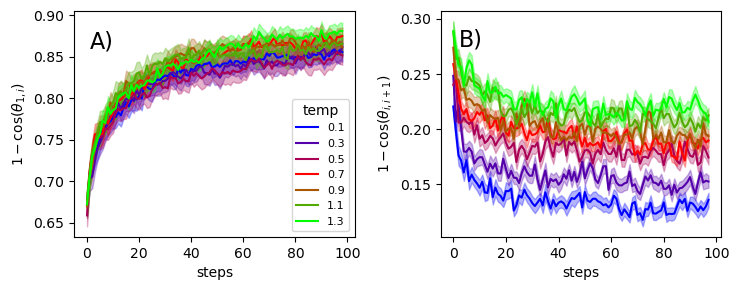

In [96]:
Ds=dict()
Ys=dict()
for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
    Y=[]
    D=[]
    for n in range(100):
        M=numpy.array(embeddings[f"{temp} {n}"])
        dists = cosine_distances(M)
        Y.append(dists[0][1:])
        d=[]
        for i in range(1,99):
            d.append(dists[i][i+1])
        D.append(d)
    Y=numpy.array(Y)
    D=numpy.array(D)
    Ds[temp]=D
    Ys[temp]=Y

# Choose a colormap (e.g., 'viridis', 'plasma', 'inferno', 'magma', 'cividis')
cmap = plt.get_cmap('brg')

figure(figsize=[7.5,3])
subplot(1,2,1)
for i,temp in enumerate([0.1,0.3,0.5,0.7,0.9,1.1,1.3]):
    m=Ys[temp].mean(0)
    s=Ys[temp].std(0)/sqrt(100)
    fill_between(range(99),m+s,m-s,alpha=0.3,color=cmap(np.linspace(0,1,7)[i]))
    plot(m,color=cmap(np.linspace(0,1,7)[i]),label=temp)
    legend(title='temp',fontsize=8)
xlabel("steps",fontsize=10)
ylabel(r"$1 - \cos(\theta_{1,i})$")
text(1,0.86,"A)",fontsize=16)    
subplot(1,2,2)
for i,temp in enumerate([0.1,0.3,0.5,0.7,0.9,1.1,1.3]):
    m=Ds[temp].mean(0)
    s=Ds[temp].std(0)/sqrt(100)
    fill_between(range(98),m+s,m-s,alpha=0.3,color=cmap(np.linspace(0,1,7)[i]))
    plot(m,color=cmap(np.linspace(0,1,7)[i]))
    xlabel("steps",fontsize=10)
    ylabel(r"$1 - \cos(\theta_{i,i+1})$")
text(2,0.275,"B)",fontsize=16)    
tight_layout()
savefig("trajectoriesThetaBoth.pdf")
show()

t = 0.1: optimal k = 15
t = 0.3: optimal k = 18
t = 0.5: optimal k = 19
t = 0.7: optimal k = 17
t = 0.9: optimal k = 18
t = 1.1: optimal k = 16
t = 1.3: optimal k = 20


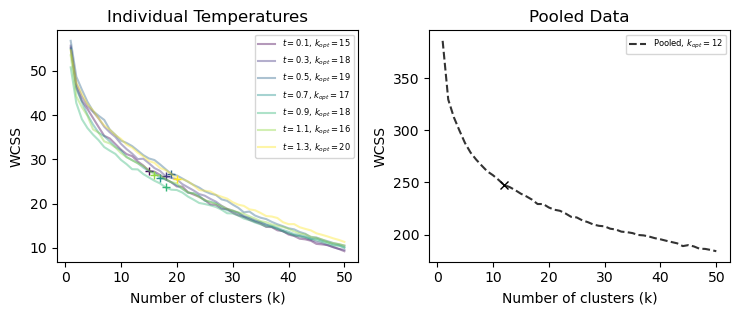


Pooled data optimal k: 12


In [150]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import cm

# Initialize figure
plt.figure(figsize=[7.5, 3.25])
cmap = cm.viridis

# =============================================
# Left subplot: Individual temperatures
# =============================================
plt.subplot(1, 2, 1)
clusterLabels = {}

for i, temp in enumerate([0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3]):
    # Load embeddings for current temperature
    EP = np.array([embeddings[f"{temp} {n}"][-1] for n in range(100)])
    
    # WCSS calculation
    k_range = range(1, 51)
    wcss = []
    CL = {}
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(EP)
        wcss.append(kmeans.inertia_)
        CL[k] = kmeans.predict(EP)
    
    # Find optimal k
    k_normalized = np.array(k_range) / max(k_range)
    wcss_normalized = np.array(wcss) / max(wcss)
    optimal_k = k_range[np.argmin(np.sqrt(k_normalized**2 + wcss_normalized**2))]
    
    # Plot
    plt.plot(k_range, wcss, linestyle='-', color=cmap(np.linspace(0, 1, 7)[i]),
             label=rf"$t={temp}$, $k_{{opt}}={optimal_k}$", alpha=0.4)
    plt.plot(optimal_k, wcss[optimal_k-1], marker='+', color=cmap(np.linspace(0, 1, 7)[i]))
    
    clusterLabels[temp] = CL[optimal_k]
    print(f"t = {temp}: optimal k = {optimal_k}")

plt.legend(fontsize=6)
plt.xlabel('Number of clusters (k)', fontsize=10)
plt.ylabel('WCSS', fontsize=10)
plt.title('Individual Temperatures', fontsize=12)

# =============================================
# Right subplot: Pooled data
# =============================================
plt.subplot(1, 2, 2)

# Create pooled dataset
pooled_EP = np.vstack([embeddings[f"{temp} {n}"][-1] 
                      for temp in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3] 
                      for n in range(100)])

# WCSS calculation for pooled data
wcss_pooled = []
CL_pooled = {}
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(pooled_EP)
    wcss_pooled.append(kmeans.inertia_)
    CL_pooled[k] = kmeans.predict(pooled_EP)

# Find optimal k for pooled data
k_normalized_pooled = np.array(k_range) / max(k_range)
wcss_normalized_pooled = np.array(wcss_pooled) / max(wcss_pooled)
optimal_k_pooled = k_range[np.argmin(np.sqrt(k_normalized_pooled**2 + wcss_normalized_pooled**2))]

# Store results
clusterLabels_pooled = CL_pooled[optimal_k_pooled]

# Plot pooled results
plt.plot(k_range, wcss_pooled, linestyle='--', color='black',
         label=rf"Pooled, $k_{{opt}}={optimal_k_pooled}$", alpha=0.8)
plt.plot(optimal_k_pooled, wcss_pooled[optimal_k_pooled-1], marker='x', color='black')

plt.legend(fontsize=6)
plt.xlabel('Number of clusters (k)', fontsize=10)
plt.ylabel('WCSS', fontsize=10)
plt.title('Pooled Data', fontsize=12)

# Final formatting
plt.tight_layout()
plt.savefig("clusterOpimality.pdf")
plt.show()

print(f"\nPooled data optimal k: {optimal_k_pooled}")

In [149]:
pickle.dump(clusterLabels,open("clusterLabels.p","wb"))
pickle.dump(clusterLabels_pooled,open("pooledClusterLabels.p","wb"))
clusterLabels[0.1]

array([ 2, 13, 13,  6,  1,  2,  0,  8,  5,  7,  2,  9,  1,  0,  5,  2, 10,
        2,  1, 11,  5,  8, 12,  6,  5, 14,  5, 11, 14,  1,  8, 14,  0,  1,
        3,  2, 12,  0,  2,  4,  1, 12,  2,  2,  2, 14,  3,  2,  0, 14,  0,
        2,  2,  2, 10,  5, 11,  9,  2,  7,  2,  0,  4,  2, 13, 12,  7,  4,
        0, 13,  4,  5, 12,  4,  5,  2,  0,  2,  3,  0,  2,  7,  1,  4,  2,
       11,  0,  2, 14, 13,  1,  6,  3,  0,  3,  7, 13,  2,  2, 12],
      dtype=int32)

In [133]:
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity

def align_to_reference(reference_centroids, target_centroids):
    # Compute cost matrix (1 - cosine similarity)
    cost_matrix = 1 - cosine_similarity(reference_centroids, target_centroids)
    
    # Solve optimal assignment (minimizes total cost)
    ref_indices, target_indices = linear_sum_assignment(cost_matrix)
    
    # Create mapping: target cluster -> reference cluster
    mapping = np.zeros_like(target_indices)
    mapping[ref_indices] = target_indices  # mapping[new_label] = old_label
    
    return mapping

# Align all clusterings to reference (1.3)
reference_key = 1.3
reference_centroids = centroids[reference_key]  # shape: (20, 384)
alignment_mappings = {}
for key in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1]:
    alignment_mappings[key] = align_to_reference(reference_centroids, centroids[key])


In [134]:
aligned_clusterLabels = {}
for key in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1]:
    original_labels = clusterLabels[key]
    aligned_labels = np.array([alignment_mappings[key][label] for label in original_labels])
    aligned_clusterLabels[key] = aligned_labels

# Add reference (1.3) as-is
aligned_clusterLabels[1.3] = clusterLabels[1.3]

In [135]:
aligned_clusterLabels[0.5]

array([13,  6, 14,  6,  1,  1, 11,  7,  4, 16,  1,  1, 10, 13, 13, 19, 16,
        3, 12, 10, 14,  1, 11,  3,  9, 17, 18, 11,  0, 11, 18, 14, 19, 14,
        2,  5, 12, 13, 18,  8,  0,  1, 13,  8,  3,  9, 10,  4,  0, 10,  4,
        4, 13, 13,  9,  3,  9,  4, 11,  8, 18,  2,  9, 10, 17,  4,  9, 11,
        1,  4,  8,  3,  0,  3,  1, 16, 13,  3, 14,  5,  4,  9,  6,  4, 11,
       11, 13,  4,  9, 17,  2, 18, 15, 16,  9, 17, 17,  3,  5, 13])

In [140]:
imagePerCluster=dict()
for i in range(20):
    idsNeeded=[]
    for temp in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1]:
        for j in range(100):
            if aligned_clusterLabels[temp][j]==i:
                idsNeeded.append([temp,j])
    imagePerCluster[i]=idsNeeded
pickle.dump(imagePerCluster,open("imagePerCluster.p","wb"))

In [137]:
idsNeeded

[[0.1, 7],
 [0.3, 36],
 [0.5, 4],
 [0.5, 5],
 [0.5, 10],
 [0.5, 11],
 [0.5, 21],
 [0.5, 41],
 [0.5, 68],
 [0.5, 74],
 [0.7, 24],
 [0.7, 36],
 [0.9, 21],
 [0.9, 96],
 [1.1, 83],
 [1.1, 84]]

In [151]:
reservoir

["As he lay in the hospital bed, his opulent lifestyle's superficial splendor revealed itself to be just a calculated performance, leaving him wondering what truly mattered.",
 'As they stood hand in hand on the weathered bench, their six-year romance blossomed into a serious and steadfast love that beat in perfect harmony.',
 'The Prime Minister pored over strategy documents, trying to sell the public on a fragile peace deal while juggling the weight of his job amidst impending military action.',
 'As the morning sun rises over the nation, eight weary travelers prepare to embark on a plan that will seem impossible to achieve, but promises to take them beyond.',
 'As I sat particularly alone, surrounded by nature, I found an old book with exactly eight pages that told a story in a forgotten language waiting to be read and understood.',
 'As students creatively bartered, they would expect the best tech support to stay out of their study sessions, securing coveted spots in a sea of milli

Embeddings computation complete!


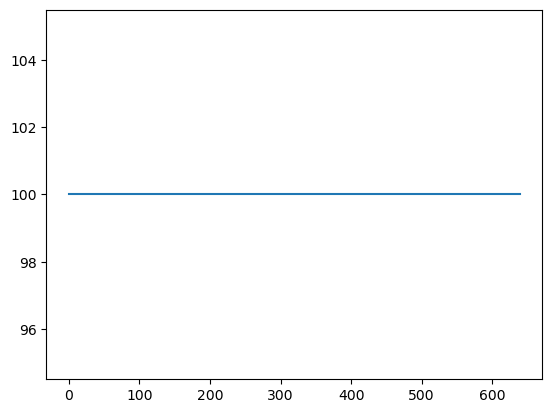

In [31]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
import pickle
import glob
import os

def read_csv_with_multiline(csv_path):
    """Read CSV file while properly handling multi-line quoted prompts"""
    rows = []
    with open(csv_path, 'r', encoding='utf-8') as f:
        reader = csv.reader(f, quotechar='"', escapechar='\\')
        header = next(reader)  # Read header
        for row in reader:
            # Reconstruct potentially split prompts
            if len(row) > 4:  # If row was split due to newlines
                row = [row[0], row[1], row[2], '"' + '|'.join(row[3:]) + '"']
            rows.append(row)
    return pd.DataFrame(rows, columns=header)

def clean_prompt(prompt):
    """Convert any prompt to a clean string"""
    if pd.isna(prompt) or prompt == 'nan':
        return ""
    if isinstance(prompt, (int, float)):
        return ""
    prompt = str(prompt).strip()
    # Handle multi-line prompts that were joined with |
    prompt = prompt.replace('|', '\n')  # Restore original newlines
    # Remove special tokens
    for token in ["!!!IMAGE!!!", "!!!ATTENTION!!!", "ids:", "http"]:
        prompt = prompt.replace(token, "")
    return prompt.strip()
    
# Initialize model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Configuration
base_path = "multi/logs"  # Path containing all CSV files
temperatures = [0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3]
conditions = [(A, B) for A in range(4) for B in range(4)]  # 16 conditions (A=0-3, B=0-3)

embeddings = {}

Y=[]
for temp in [0.7]:
    for A, B in conditions:
        for n in range(40):  # 100 replicates
            filename = f"{base_path}/run_{n:03}_rep_0_gen_{A}_desc_{B}_temp_{temp}.csv"
            
            if not os.path.exists(filename):
                print(f"Missing: {filename}")
                continue
                
            try:
                #data = pd.read_csv(filename)
                data = read_csv_with_multiline(filename)
            
                # Clean all prompts
                data['clean_prompt'] = data['prompt'].apply(clean_prompt)
                
                # Get valid prompts
                valid_data = data[data['clean_prompt'].str.len() > 0]

                Y.append(len(data))
                if len(data) < 100:  # Adjust based on expected steps
                    #print(f"Incomplete: {filename} (steps={len(data)})")
                    print(f"python multi.py {n} 0.7 {A} {B}")
                # Compute embeddings for all prompts in this run
                key = f"temp_{temp}_gen_{A}_desc_{B}_run_{n}"
                embeddings[key] = model.encode(data['clean_prompt'].tolist())
                
            except Exception as e:
                print(f"Error processing {filename}: {str(e)}")
                Y.append(0)

# Save embeddings
with open("all_embeddings_16conditions.pkl", "wb") as f:
    pickle.dump(embeddings, f)
    
print("Embeddings computation complete!")
plot(Y)
show(Y)

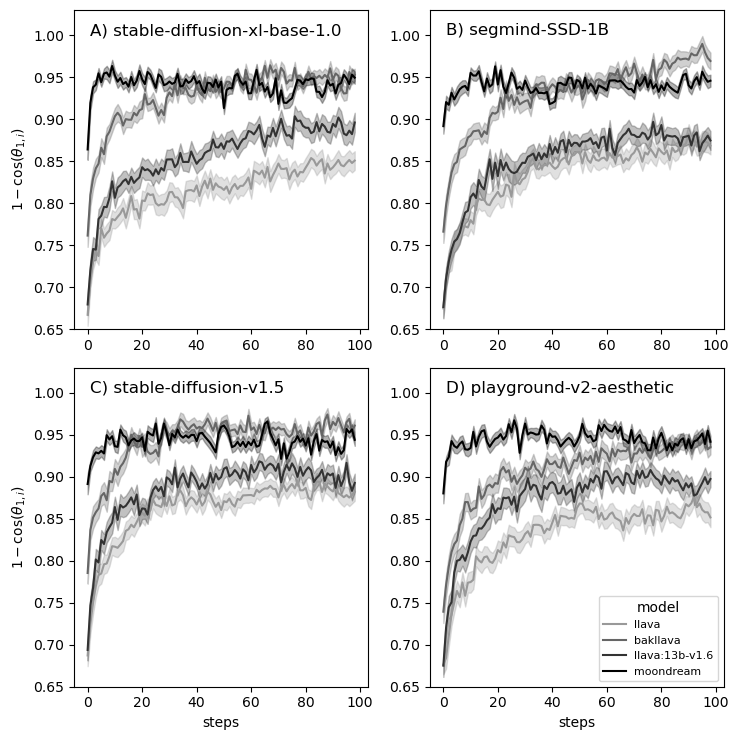

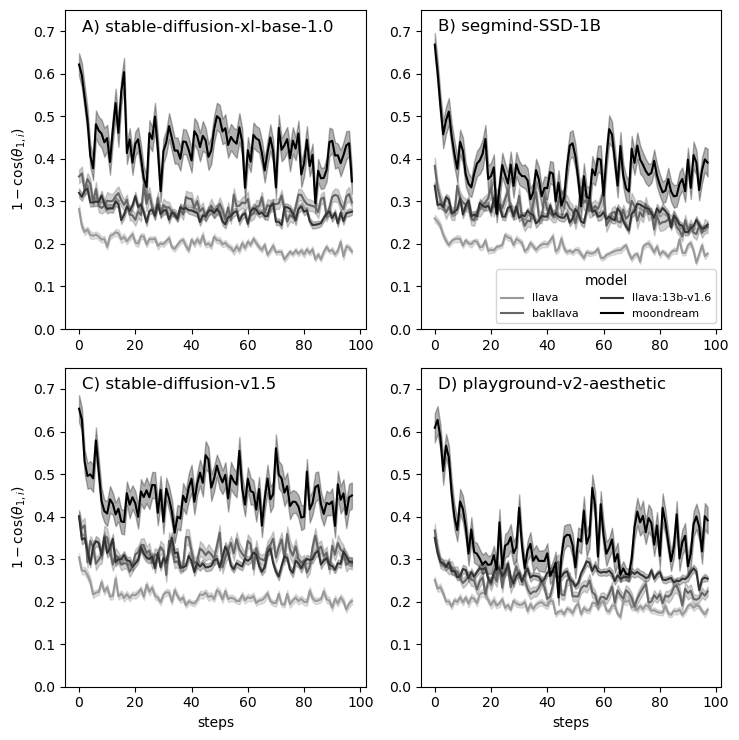

In [93]:
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_distances
from numpy import sqrt
import numpy as np
import pickle

# Load cleaned embeddings
with open("all_embeddings_16conditions.pkl", "rb") as f:
    embeddings = pickle.load(f)

# Configuration
conditions = [(A, B) for A in range(4) for B in range(4)]  # 16 conditions
temp = 0.7  # Single temperature value

# Prepare plot
#plt.figure(figsize=(15, 12))

colors = [
    # Grays (light to dark)
    (0.6, 0.6, 0.6), (0.4, 0.4, 0.4),
    (0.2, 0.2, 0.2), (0.0, 0.0, 0.0),
    
    # Grays (light to dark)
    (0.6, 0.6, 0.6), (0.4, 0.4, 0.4),
    (0.2, 0.2, 0.2), (0.0, 0.0, 0.0),
    
    # Grays (light to dark)
    (0.6, 0.6, 0.6), (0.4, 0.4, 0.4),
    (0.2, 0.2, 0.2), (0.0, 0.0, 0.0),
    
    # Grays (light to dark)
    (0.6, 0.6, 0.6), (0.4, 0.4, 0.4),
    (0.2, 0.2, 0.2), (0.0, 0.0, 0.0)
]


Ds=dict()
Ys=dict()
for condition_idx, (A, B) in enumerate(conditions):
    #plt.subplot(4, 4, condition_idx + 1)
    
    temp_dists = []
    temp=0.7
    Y=[]
    D=[]
    for n in range(40):
        key = f"temp_{temp}_gen_{A}_desc_{B}_run_{n}"
        M = numpy.array(embeddings[key])
        dists = cosine_distances(M)
        Y.append(dists[0][1:])
        d=[]
        for i in range(1,99):
            d.append(dists[i][i+1])
        D.append(d)
    Y=numpy.array(Y)
    D=numpy.array(D)
    Ds[condition_idx]=D
    Ys[condition_idx]=Y

# Choose a colormap (e.g., 'viridis', 'plasma', 'inferno', 'magma', 'cividis')
cmap = plt.get_cmap('brg')
theLetter=[
    "A","","","",
    "B","","","",
    "C","","","",
    "D","","",""]
generators=[
    "stable-diffusion-xl-base-1.0", 
    "segmind-SSD-1B", 
    "stable-diffusion-v1.5",
    "playground-v2-aesthetic"
]
desc=[
    "llava",        # 0
    "bakllava",     # 1
    "llava:13b-v1.6",   # 2
    "moondream"]    # 3
figure(figsize=[7.5,7.5])
for condition_idx, (A, B) in enumerate(conditions):
    subplot(2,2,(condition_idx>>2)+1)

    m=Ys[condition_idx].mean(0)
    s=Ys[condition_idx].std(0)/sqrt(100)
    fill_between(range(99),m+s,m-s,alpha=0.3,color=colors[condition_idx])
    plot(m,color=colors[condition_idx],label=desc[condition_idx&3])
    if condition_idx==15:
        legend(title='model',fontsize=8)
    if condition_idx in [0,4,8,12]:
        text(1,1.0,f"{theLetter[condition_idx]}) {generators[condition_idx>>2]}",fontsize=12)    
    ylim(0.65,1.03)   
    if condition_idx in [8,12]:
        xlabel("steps",fontsize=10)
    if condition_idx in [0,8]:
        ylabel(r"$1 - \cos(\theta_{1,i})$")
tight_layout()
savefig("trajectoriesMixedModelsA.pdf")
show()

figure(figsize=[7.5,7.5])
for condition_idx, (A, B) in enumerate(conditions):
    subplot(2,2,(condition_idx>>2)+1)

    m=Ds[condition_idx].mean(0)
    s=Ds[condition_idx].std(0)/sqrt(100)
    fill_between(range(98),m+s,m-s,alpha=0.3,color=colors[condition_idx])
    plot(m,color=colors[condition_idx],label=desc[condition_idx&3])
    if condition_idx==7:
        legend(title='model',fontsize=8,ncol=2,loc=4)
    if condition_idx in [0,4,8,12]:
        text(1,0.7,f"{theLetter[condition_idx]}) {generators[condition_idx>>2]}",fontsize=12)    
    ylim(0.0,0.75)   
    if condition_idx in [8,12]:
        xlabel("steps",fontsize=10)
    if condition_idx in [0,8]:
        ylabel(r"$1 - \cos(\theta_{1,i})$")
tight_layout()
savefig("trajectoriesMixedModelsB.pdf")
show()

In [94]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances

# Load your embeddings (assuming dictionary format)
with open("all_embeddings_16conditions.pkl", "rb") as f:
    embeddings_dict = pickle.load(f)

# Initialize storage
conditions = [(a, b) for a in range(4) for b in range(4)]
final_distances = {cond: [] for cond in conditions}

# Process each run
for key in embeddings_dict:
        
    # Parse condition from key (format: "temp_0.7_gen_A_desc_B_run_N")
    parts = key.split('_')
    A, B = int(parts[3]), int(parts[5])
    
    # Get embeddings for this run (shape: [steps, embedding_dim])
    run_embeddings = embeddings_dict[key]
    if len(run_embeddings) < 2:  # Need at least initial and final
        continue
        
    # Calculate distance between first and last step
    initial = run_embeddings[0]
    final = run_embeddings[-1]
    distance = 1 - np.dot(initial, final)/(np.linalg.norm(initial)*np.linalg.norm(final))
    final_distances[(A, B)].append(distance)

# Convert to analysis DataFrame
rows = []
for (A, B), distances in final_distances.items():
    for dist in distances:
        rows.append({'A': A, 'B': B, 'distance': dist})
df = pd.DataFrame(rows)

# Now run your ANOVA analysis on this df
print(df.groupby(['A', 'B']).describe())  # Quick stats by condition

    distance                                                              \
       count      mean       std       min       25%       50%       75%   
A B                                                                        
0 0     40.0  0.850613  0.112792  0.565500  0.795112  0.836437  0.928610   
  1     40.0  0.952870  0.072718  0.800132  0.895773  0.945677  1.002512   
  2     40.0  0.895980  0.117497  0.523561  0.813790  0.920465  0.977653   
  3     40.0  0.949393  0.073265  0.782233  0.911905  0.960272  1.007570   
1 0     40.0  0.868280  0.104548  0.629554  0.800722  0.866890  0.937701   
  1     40.0  0.969273  0.101206  0.664962  0.920719  0.981555  1.036016   
  2     40.0  0.874570  0.114148  0.613794  0.783145  0.906269  0.965910   
  3     40.0  0.945761  0.072626  0.784183  0.893895  0.964538  0.996183   
2 0     40.0  0.882270  0.109581  0.649533  0.827817  0.868827  0.951885   
  1     40.0  0.961093  0.075934  0.807699  0.909593  0.967362  1.020053   
  2     40.0

ANOVA Results:
             sum_sq     df          F        PR(>F)
C(A)       0.014859    3.0   0.534153  6.590074e-01
C(B)       0.924696    3.0  33.241879  6.087871e-20
C(A):C(B)  0.051985    9.0   0.622933  7.779774e-01
Residual   5.785979  624.0        NaN           NaN


Effect Sizes (η²):
A: 0.002
B: 0.136
Interaction: 0.008


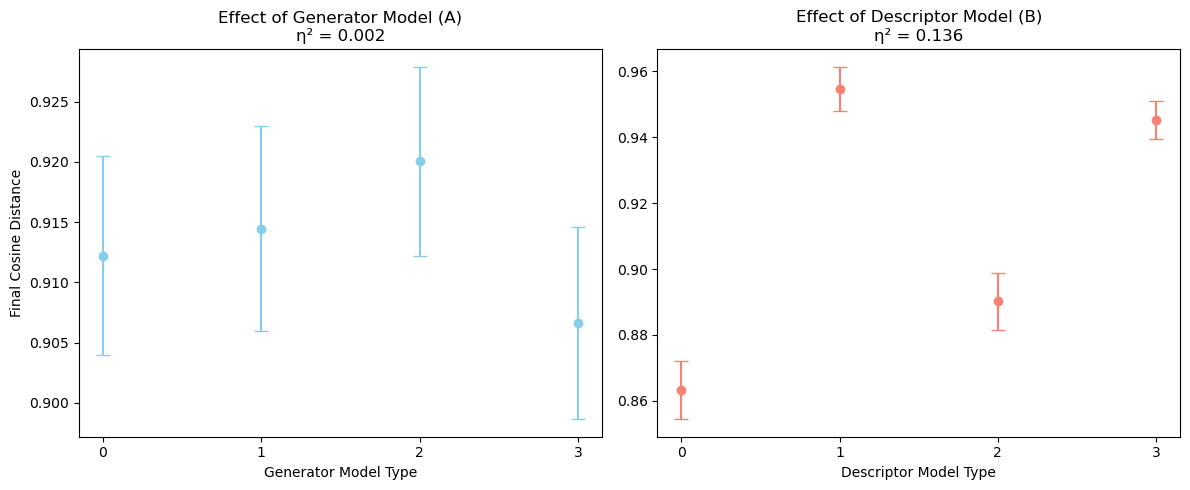

In [99]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt
import numpy as np

# 1. Perform Two-Way ANOVA
model = ols('distance ~ C(A) + C(B) + C(A):C(B)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

# Print ANOVA results
print("ANOVA Results:")
print(anova_table)
print("\n")

# 2. Calculate Effect Sizes (Eta-squared)
ss_total = anova_table['sum_sq'].sum()
eta2 = {
    'A': anova_table.loc['C(A)', 'sum_sq'] / ss_total,
    'B': anova_table.loc['C(B)', 'sum_sq'] / ss_total,
    'Interaction': anova_table.loc['C(A):C(B)', 'sum_sq'] / ss_total
}

print("Effect Sizes (η²):")
for factor, size in eta2.items():
    print(f"{factor}: {size:.3f}")

# 3. Visualize Results with Matplotlib
plt.figure(figsize=(12, 5))

# Main effects plot for A
plt.subplot(1, 2, 1)
for a in sorted(df['A'].unique()):
    subset = df[df['A'] == a]
    mean = subset['distance'].mean()
    std = subset['distance'].std()
    n = len(subset)
    plt.errorbar(a, mean, yerr=std/np.sqrt(n), 
                fmt='o', color='skyblue', capsize=5)
plt.title("Effect of Generator Model (A)\nη² = {:.3f}".format(eta2['A']))
plt.xlabel("Generator Model Type")
plt.ylabel("Final Cosine Distance")
plt.xticks(sorted(df['A'].unique()))

# Main effects plot for B
plt.subplot(1, 2, 2)
for b in sorted(df['B'].unique()):
    subset = df[df['B'] == b]
    mean = subset['distance'].mean()
    std = subset['distance'].std()
    n = len(subset)
    plt.errorbar(b, mean, yerr=std/np.sqrt(n), 
                fmt='o', color='salmon', capsize=5)
plt.title("Effect of Descriptor Model (B)\nη² = {:.3f}".format(eta2['B']))
plt.xlabel("Descriptor Model Type")
plt.xticks(sorted(df['B'].unique()))

plt.tight_layout()
plt.show()

# 4. Interaction Plot (if significant)
if 'C(A):C(B)' in anova_table.index and anova_table.loc['C(A):C(B)', 'PR(>F)'] < 0.05:
    plt.figure(figsize=(8, 6))
    
    colors = plt.cm.viridis(np.linspace(0, 1, len(df['B'].unique())))
    
    for i, b in enumerate(sorted(df['B'].unique())):
        subset = df[df['B'] == b]
        means = []
        std_errs = []
        for a in sorted(df['A'].unique()):
            group = subset[subset['A'] == a]
            means.append(group['distance'].mean())
            std_errs.append(group['distance'].std()/np.sqrt(len(group)))
        
        plt.errorbar(sorted(df['A'].unique()), means, yerr=std_errs,
                    fmt='-o', color=colors[i], label=f'B={b}', capsize=5)
    
    plt.title("Interaction Between A and B\nη² = {:.3f}".format(eta2['Interaction']))
    plt.xlabel("Generator Model (A)")
    plt.ylabel("Final Cosine Distance")
    plt.legend(title="Descriptor Model (B)")
    plt.xticks(sorted(df['A'].unique()))
    plt.grid(True, alpha=0.2)
    plt.show()

python(54895) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 14.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]
